In [7]:
%pip install -U google-genai python-dotenv 

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: C:\Users\KARTIK SRIBVASTAVA\AppData\Local\Python\pythoncore-3.14-64\python.exe -m pip install --upgrade pip


In [8]:
import os
from google import genai
from dotenv import load_dotenv


In [9]:
load_dotenv()


True

In [10]:
api_key = os.getenv("GEMINI_API_KEY")

In [11]:
client = genai.Client(api_key = api_key)
model = "gemini-3.5-flash-lite"
print("api key loaded")

api key loaded


In [12]:
from agent.tools import calc
print(calc(10,5,"multiply"))

50


In [13]:

from google.genai import types

calc_dec = types.FunctionDeclaration(
    name="calc",
    description="Perform arithmetic operations on two numbers.",
    parameters={
        "type": "OBJECT",
        "properties": {
            "operation": {
                "type": "STRING",
                "description": "Operation to be performed",
                "enum": ["add", "subtract", "multiply", "divide"]
            },
            "a": {
                "type": "NUMBER",
                "description": "First number"
            },
            "b": {
                "type": "NUMBER",
                "description": "Second number"
            }
        },
        "required": ["operation", "a", "b"]
    }
)

calc_tool = types.Tool(
    function_declarations=[calc_dec]
)

print("Tool declaration created successfully!")


Tool declaration created successfully!


In [14]:
response = client.models.generate_content(
    model=model,
    contents="Calculate 245 multiplied by 18",
    config={"tools": [calc_tool]}
)

print(response.function_calls)

[FunctionCall(
  args={
    'a': 245,
    'b': 18,
    'operation': 'multiply'
  },
  id='call_1430125',
  name='calc'
)]


In [15]:

function_call = response.function_calls[0]

result = calc(**function_call.args)

response2 = client.models.generate_content(
    model=model,
    contents=[
        "Calculate 245 multiplied by 18",
        response.candidates[0].content,
        types.Content(
            role="user",
            parts=[
                types.Part.from_function_response(
                    name=function_call.name,
                    response={"result": result}
                )
            ]
        )
    ],
    config={"tools": [calc_tool]}
)

print(response2.text)


245 multiplied by 18 is 4,410.


In [16]:
tools = {
    "calc": calc
}
tool = tools["calc"]
result = tool(
    operation="multiply",
    a=245,
    b=18
)
print(result)


4410


In [17]:

response = client.models.generate_content(
    model=model,
    contents="Calculate 245 multiplied by 18",
    config={"tools": [calc_tool]}
)

print(response.function_calls)


[FunctionCall(
  args={
    'a': 245,
    'b': 18,
    'operation': 'multiply'
  },
  id='call_1540333',
  name='calc'
)]


In [18]:

call = response.function_calls[0]

tool = tools[call.name]

result = tool(**call.args)

print(result)


4410


In [19]:
def square(n):
    return n * n

tools = {
    "calc": calc,
    "square": square
}

square_dec = types.FunctionDeclaration(
    name="square",
    description="Calculate the square of a number.",
    parameters={
        "type": "OBJECT",
        "properties": {
            "n": {"type": "NUMBER"}
        },
        "required": ["n"]
    }
)

square_tool = types.Tool(
    function_declarations=[square_dec]
)

In [20]:
all_tools = [calc_tool, square_tool]

In [21]:
response = client.models.generate_content(
    model=model,
    contents="Calculate the square of 12.",
    config={"tools": all_tools}
)
name = "square"
args = {"n": 12}

In [22]:
call = response.function_calls[0]
tool = tools[call.name]
result = tool(**call.args)
result

144

In [23]:

from langchain.tools import tool
@tool
def multiply(a: float, b: float) -> float:
    """Multiply two numbers."""
    return a * b
print(multiply.name)
print(multiply.description)
print(multiply.invoke({"a": 10, "b": 5}))

multiply
Multiply two numbers.
50.0


In [24]:
from pydantic import BaseModel, Field
class CalculatorInput(BaseModel):
    a: float = Field(description="First number")
    b: float = Field(description="Second number")
    operation: str = Field(description="Operation to perform")
    
@tool(args_schema=CalculatorInput)
def calculator(a: float, b: float, operation: str) -> float:
    """Perform basic arithmetic operations."""

    if operation == "add":
        return a + b
    elif operation == "subtract":
        return a - b
    elif operation == "multiply":
        return a * b
    elif operation == "divide":
        return a / b
    else:
        return "Invalid operation"
    
result = calculator.invoke({
    "a": 20,
    "b": 5,
    "operation": "multiply"
})

print(result)

100.0


In [25]:
from langchain_core.tools import StructuredTool

In [26]:
def get_employee(name: str, department: str):
    return f"{name} works in {department} department."

employee_tool = StructuredTool.from_function(
    func=get_employee,
    name="get_employee",
    description="Get employee information using name and department."
)

result = employee_tool.invoke({
    "name": "Kartik",
    "department": "Engineering"
})

print(result)

Kartik works in Engineering department.


In [27]:
from langchain.tools import BaseTool
class SquareTool(BaseTool):
    name: str = "square"
    description: str = "Calculate the square of a number."

    def _run(self, n: float) -> float:
        return n * n
    
square_tool = SquareTool()
result = square_tool.invoke({"n": 8})
result

64

In [28]:
@tool
def add(a: int, b: int) -> int:
    """Add two numbers."""
    return a + b
@tool
def subtract(a: int, b: int) -> int:
    """Subtract two numbers."""
    return a - b

calculator_toolkit = [add, subtract]
for t in calculator_toolkit:
    print(t.name)

add
subtract


In [29]:
result = calculator_toolkit[0].invoke({
    "a": 20,
    "b": 10
})
result

30

In [30]:
from langchain_google_genai import ChatGoogleGenerativeAI
llm = ChatGoogleGenerativeAI(
    model="gemini-3.5-flash-lite",
    google_api_key=api_key
)
llm_with_tools = llm.bind_tools(calculator_toolkit)
response = llm_with_tools.invoke(
    "What is 250 plus 150?"
)

In [31]:
response.tool_calls

[{'name': 'add',
  'args': {'a': 250, 'b': 150},
  'id': 'call_1427974',
  'type': 'tool_call'}]

In [32]:
from langchain.agents import create_agent
agent = create_agent(
    model=llm,
    tools=calculator_toolkit,
    system_prompt="You are a helpful calculator assistant."
)
response = agent.invoke({
    "messages": [
        {"role": "user", "content": "What is 250 plus 150?"}
    ]
})
response["messages"][-1].content

[{'type': 'text',
  'text': '250 plus 150 is 400.',
  'extras': {'signature': 'EmAKXgFpFH0TOM9jVjQA/PizxJhNc9anSVqEd1Sy4A+tHixQmXKUzJU1DOMRC+eoA5fF13ParMdYJYsw8/VFG/a+N6CT543C6rrmQIrBGI04LfMrpni0RuYQqiqAURannZc='}}]

In [33]:
from typing import TypedDict
from langgraph.graph import StateGraph, START, END

class State(TypedDict):
    question: str
    result: str

In [34]:
def document_search(state):
    return {
        "result": "Searching company documents..."
    }


def data_analysis(state):
    return {
        "result": "Analyzing business data..."
    }

In [35]:
def router(state):

    question = state["question"]

    prompt = f"""
    You are a routing assistant.

    Decide which category this question belongs to:

    documents: Questions about company policies, rules, handbooks,
    procedures and documentation.

    analytics: Questions about sales, revenue, employees,
    performance and numerical data.

    Question: {question}

    Reply with only documents or analytics.
    """

    response = llm.invoke(prompt)

    content = response.content

    if isinstance(content, list):
        answer = " ".join(
            item.get("text", "")
            for item in content
            if isinstance(item, dict)
        )
    else:
        answer = str(content)

    answer = answer.strip().lower()

    print("Selected route:", answer)

    if "documents" in answer:
        return "documents"

    return "analytics"

In [36]:
def router(state):
    print("ROUTER FUNCTION CALLED")
    question = state["question"]

    prompt = f"""
    Decide which tool is needed.

    Question: {question}

    Reply with only one word:
    documents or analytics
    """

    response = llm.invoke(prompt)

    if isinstance(response, dict):
        answer = response.get("content", response.get("text", ""))
    else:
        answer = response.content

    if isinstance(answer, list):
        answer = " ".join(
            item if isinstance(item, str)
            else item.get("text", "") if isinstance(item, dict)
            else str(item)
            for item in answer
        )
    print("Gemini response:", answer)
    answer = str(answer).strip().lower()
    if "documents" in answer:
        return "documents"

    return "analytics"

In [37]:
builder = StateGraph(State)

builder.add_node("documents", document_search)
builder.add_node("analytics", data_analysis)

builder.add_conditional_edges(
    START,
    router,
    {
        "documents": "documents",
        "analytics": "analytics"
    }
)

builder.add_edge("documents", END)
builder.add_edge("analytics", END)

graph = builder.compile()

In [38]:
result = graph.invoke({
    "question": "Where can I find the work from home rules?",
    "result": ""
})

print(result["result"])

ROUTER FUNCTION CALLED
Gemini response: documents
Searching company documents...


In [39]:
result = graph.invoke({
    "question": "What is the total sales revenue this month?",
    "result": ""
})

print(result["result"])

ROUTER FUNCTION CALLED
Gemini response: analytics
Analyzing business data...


In [40]:
import pandas as pd

In [41]:
sales_data = pd.DataFrame({
    "employee": ["Aman", "Riya", "Kartik", "Aman", "Riya"],
    "region": ["North", "South", "North", "West", "South"],
    "sales": [50000, 70000, 60000, 40000, 80000]
})

sales_data

,employee,region,sales
0,Aman,North,50000
1,Riya,South,70000
2,Kartik,North,60000
3,Aman,West,40000
4,Riya,South,80000


In [42]:
@tool
def get_total_sales(region: str = "all") -> str:
    """Calculate total sales. Optionally filter by region."""

    if region.lower() == "all":
        total = sales_data["sales"].sum()
    else:
        total = sales_data[
            sales_data["region"].str.lower() == region.lower()
        ]["sales"].sum()

    return f"Total sales: ₹{total:,}"

print(get_total_sales.invoke({"region": "North"}))

Total sales: ₹110,000


In [43]:
tools = [get_total_sales]

llm_with_tools = llm.bind_tools(tools)

In [44]:
from typing import Annotated
from typing_extensions import TypedDict
from langgraph.graph.message import add_messages
from langgraph.prebuilt import ToolNode, tools_condition

class AgentState(TypedDict):
    messages: Annotated[list, add_messages]


def assistant(state):
    response = llm_with_tools.invoke(state["messages"])
    return {"messages": [response]}


builder = StateGraph(AgentState)

builder.add_node("assistant", assistant)
builder.add_node("tools", ToolNode(tools))

builder.add_edge(START, "assistant")

builder.add_conditional_edges(
    "assistant",
    tools_condition
)

builder.add_edge("tools", "assistant")

analytics_graph = builder.compile()

In [45]:
response = analytics_graph.invoke({
    "messages": [
        {
            "role": "user",
            "content": "Calculate total sales in the North region."
        }
    ]
})

print(response["messages"][-1].content)

[{'type': 'text', 'text': 'Total sales in the North region: ₹110,000', 'extras': {'signature': 'EmAKXgFpFH0TKImAog+CGyjx6crGzE63d005QBi7jR/eMOrj3S/eNLZv9HYbNmwQByq+af00YvR6bTQkSjBGZlP6OH4jP3ppJ4C8I8891VIkwI7PzXONCmxCPJNK48lB6Dg='}}]


In [46]:
@tool
def compare_region_sales() -> str:
    """Compare total sales across all regions."""

    result = sales_data.groupby("region")["sales"].sum()

    return result.to_string()


@tool
def get_top_employee() -> str:
    """Find the employee with the highest total sales."""

    result = sales_data.groupby("employee")["sales"].sum()

    employee = result.idxmax()
    total = result.max()

    return f"Top employee: {employee}, Sales: ₹{total:,}"

tools = [
    get_total_sales,
    compare_region_sales,
    get_top_employee
]
llm_with_tools = llm.bind_tools(tools)

In [47]:
class AgentState(TypedDict):
    messages: Annotated[list, add_messages]


def assistant(state):
    response = llm_with_tools.invoke(state["messages"])
    return {"messages": [response]}


builder = StateGraph(AgentState)

builder.add_node("assistant", assistant)
builder.add_node("tools", ToolNode(tools))

builder.add_edge(START, "assistant")

builder.add_conditional_edges(
    "assistant",
    tools_condition
)

builder.add_edge("tools", "assistant")

analytics_graph = builder.compile()

In [48]:
response = analytics_graph.invoke({"messages": [{"role": "user", "content": "Calculate total sales in the North region."}]})
print(response["messages"][-1].content)

[{'type': 'text', 'text': 'Total sales in the North region: ₹110,000', 'extras': {'signature': 'EmAKXgFpFH0TS43kYSV3B5NIzlNPaZ2q/WtAg3S/Bw7XynkF0YrWXYHs0axi5soDekLtWTW69NXM+z4i/SJzxEJsw6+KHF6fGYpPH9yCxatRsD68nH0UrmBayUOjPurEYYg='}}]


In [49]:
response = analytics_graph.invoke({"messages": [{"role": "user", "content": "Compare sales across all regions."}]})
print(response["messages"][-1].content)

[{'type': 'text', 'text': 'Here is the comparison of total sales across all regions:\n\n* **South:** $150,000\n* **North:** $110,000\n* **West:** $40,000\n\nThe South region has the highest sales, followed by the North and the West.', 'extras': {'signature': 'EmAKXgFpFH0Tcdez0zIk9mnFgpbFMnciijZdVWrl5/wQVM8Py4I9df/qd+KS2KMbOng3sLhgP8AzWv7QDHe7d/UJ0f0FZ38tY/STGBZpqcHM4+wkAKjsDg1qqqZcwd42NZE='}}]


In [50]:
response = analytics_graph.invoke({"messages": [{"role": "user", "content": "Who is the top-performing employee?"}]})
print(response["messages"][-1].content)

[{'type': 'text', 'text': 'The top-performing employee is Riya, with total sales of ₹150,000.', 'extras': {'signature': 'EmAKXgFpFH0TXF7j7yUGIa7nodhLGK444Pv88WjXPvTpjVKi76CZXV3wmr9+GQS2maa/vIMqVHNu/lLoJ40PtdihbMwKy7SeqGJjZUJeSwZDVj7W1EMXaOv40OORTxXRXek='}}]


In [51]:
from langgraph.checkpoint.memory import MemorySaver
memory = MemorySaver()
analytics_graph = builder.compile(
    checkpointer=memory
)
config = {
    "configurable": {
        "thread_id": "kartik_conversation_1"
    }
}

In [52]:
response = analytics_graph.invoke(
    {
        "messages": [
            {
                "role": "user",
                "content": "Who is the top-performing employee?"
            }
        ]
    },
    config=config
)

response["messages"][-1].content

[{'type': 'text',
  'text': 'The top-performing employee is Riya, with total sales of ₹150,000.',
  'extras': {'signature': 'EmAKXgFpFH0T4fRRY/7+X/IDi1ROTVQ1i5awZGU8KCUTmlye2u7wlXR1XE+CP0qpb8DtDBNYq2O+aMColRGdSIEQpcQXhGxzvDNhMC2n7H/04x+j+Ahi8/9j+4hoJMiBMc4='}}]

In [53]:
response = analytics_graph.invoke(
    {
        "messages": [
            {
                "role": "user",
                "content": "How much did he sell?"
            }
        ]
    },
    config=config
)

response["messages"][-1].content

[{'type': 'text',
  'text': 'Riya sold a total of ₹150,000.',
  'extras': {'signature': 'EmAKXgFpFH0TyBLqxVHH8lhxl/uKIQ35VXwn3jDNSu4NY03eTj6o/mXqrbP4kST3DgEEbQ5utvQ6VkCMu4Dg3Ywtv3U5EJELCu/8x+6l6SLYJARnOTGJJdYiatxV3uRfrZo='}}]

In [54]:
new_config = {
    "configurable": {
        "thread_id": "new_conversation"
    }
}

In [55]:
%pip install -U langgraph-checkpoint-sqlite

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: C:\Users\KARTIK SRIBVASTAVA\AppData\Local\Python\pythoncore-3.14-64\python.exe -m pip install --upgrade pip


In [56]:
from langgraph.checkpoint.sqlite import SqliteSaver
import sqlite3

In [57]:
conn = sqlite3.connect(
    "enterprise_memory.db",
    check_same_thread=False
)

memory = SqliteSaver(conn)

In [58]:
memory.setup()
analytics_graph = builder.compile(
    checkpointer=memory
)
config = {
    "configurable": {
        "thread_id": "kartik_sqlite_chat"
    }
}

In [59]:
response = analytics_graph.invoke(
    {
        "messages": [
            {
                "role": "user",
                "content": "Who is our top-performing employee?"
            }
        ]
    },
    config=config
)

response["messages"][-1].content

[{'type': 'text',
  'text': 'Our top-performing employee is Riya, with total sales of ₹150,000.',
  'extras': {'signature': 'EmAKXgFpFH0T/3GIJQcKSXrLpJ1WkogCwYOah4B8BHTsB/HXUoE4ORgZcbuIRT6WOo/oWo/Aq2A9QCioOK9dscITSxS9OndmVKw1TQ0gH2/KlI1ZGyCgnPtNvQSnoyr++DQ='}}]

In [60]:
response = analytics_graph.invoke(
    {
        "messages": [
            {
                "role": "user",
                "content": "How much did he sell?"
            }
        ]
    },
    config=config
)

print(response["messages"][-1].content)

[{'type': 'text', 'text': 'Riya sold a total of ₹150,000.', 'extras': {'signature': 'EmAKXgFpFH0T8kXN+6MuM1JsEHXCRwr7TuUn5S48gbvLrxAwzv1FPxT2rUrvLkiwF5XjSWV5HGcyB1apirNRmeOWsy6E22SflJiJjYJMunKsB3/jp2kjzMBzrD2gK71t3uM='}}]


In [61]:
response = analytics_graph.invoke(
    {
        "messages": [
            {
                "role": "user",
                "content": "Who did we discuss earlier?"
            }
        ]
    },
    config=config
)

print(response["messages"][-1].content)

[{'type': 'text', 'text': 'Earlier, we discussed Riya, our top-performing employee who achieved total sales of ₹150,000.', 'extras': {'signature': 'EmAKXgFpFH0TNwpruvbHfMqKp7hDVJFDITa3RIjOrfppOLiFbuq/VZ/h9wU77dMOpymQZW1xYl5zE1kzHTcpocnlBMNX70Ea9owONevdH9HvJa0mewa2lPx9ni2804Xs6+o='}}]


In [62]:
%pip install -U pypdf langchain-community langchain-text-splitters langchain-google-genai faiss-cpu

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: C:\Users\KARTIK SRIBVASTAVA\AppData\Local\Python\pythoncore-3.14-64\python.exe -m pip install --upgrade pip


In [63]:
from pathlib import Path
from langchain_community.document_loaders import PyPDFLoader

C:\Users\KARTIK SRIBVASTAVA\AppData\Local\Temp\ipykernel_18972\1909073654.py:2: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.document_loaders import PyPDFLoader


In [64]:
documents = []
folder = Path("data/documents")
for file in folder.glob("*.pdf"):
    loader = PyPDFLoader(str(file))
    documents.extend(loader.load())

print("Total pages loaded:", len(documents))

Total pages loaded: 645


In [65]:
print("Number of documents:", len(documents))

print("First page object:")
print(documents[0])

print("Extracted text:")
print(repr(documents[0].page_content[:500]))

Number of documents: 645
First page object:
page_content='' metadata={'producer': 'Microsoft® Word 2021', 'creator': 'Microsoft® Word 2021', 'creationdate': '2026-10-31T18:47:51+05:30', 'moddate': '2026-10-31T18:47:51+05:30', 'source': 'data\\documents\\2026_AnnualReport.pdf', 'total_pages': 88, 'page': 0, 'page_label': '1'}
Extracted text:
''


In [66]:
empty_pages = sum(
    1 for doc in documents if not doc.page_content.strip()
)

print("Empty pages:", empty_pages)
print("Non-empty pages:", len(documents) - empty_pages)

Empty pages: 22
Non-empty pages: 623


In [67]:
for doc in documents:
    if not doc.page_content.strip():
        print(
            doc.metadata["source"],
            "Page:", doc.metadata["page"] + 1
        )

for doc in documents:
    if doc.page_content.strip():
        print("Source:", doc.metadata["source"])
        print("Page:", doc.metadata["page"] + 1)
        print(doc.page_content[:500])
        break
    
total_chars = sum(len(doc.page_content) for doc in documents)

print("Total extracted characters:", total_chars)

data\documents\2026_AnnualReport.pdf Page: 1
data\documents\2026_AnnualReport.pdf Page: 2
data\documents\2026_AnnualReport.pdf Page: 87
data\documents\2026_AnnualReport.pdf Page: 88
data\documents\IDU-25d3c0ca-9bc0-4254-9063-47bc27942696.pdf Page: 2
data\documents\IDU-25d3c0ca-9bc0-4254-9063-47bc27942696.pdf Page: 4
data\documents\IDU-25d3c0ca-9bc0-4254-9063-47bc27942696.pdf Page: 16
data\documents\IDU-25d3c0ca-9bc0-4254-9063-47bc27942696.pdf Page: 20
data\documents\IDU-25d3c0ca-9bc0-4254-9063-47bc27942696.pdf Page: 40
data\documents\IDU-25d3c0ca-9bc0-4254-9063-47bc27942696.pdf Page: 46
data\documents\IDU-25d3c0ca-9bc0-4254-9063-47bc27942696.pdf Page: 48
data\documents\IDU-25d3c0ca-9bc0-4254-9063-47bc27942696.pdf Page: 66
data\documents\IDU-25d3c0ca-9bc0-4254-9063-47bc27942696.pdf Page: 116
data\documents\IDU-25d3c0ca-9bc0-4254-9063-47bc27942696.pdf Page: 208
data\documents\IDU-25d3c0ca-9bc0-4254-9063-47bc27942696.pdf Page: 252
data\documents\IDU-25d3c0ca-9bc0-4254-9063-47bc27942696.pd

In [68]:
documents = [
    doc for doc in documents
    if doc.page_content.strip()
]

print("Pages after cleaning:", len(documents))

Pages after cleaning: 623


In [69]:
from langchain_text_splitters import RecursiveCharacterTextSplitter

In [70]:
text_splitter = RecursiveCharacterTextSplitter(
    chunk_size=1000,
    chunk_overlap=200
)

chunks = text_splitter.split_documents(documents)
print("Total chunks:", len(chunks))
print(chunks[0].page_content)
print(chunks[0].metadata)

Total chunks: 2030
1 
 
Building the Frontier Ecosystem 
Dear shareholders, colleagues, customers, and partners: 
For Microsoft, the central question as we enter this Super Intelligence era is not just how big the opportunity becomes, but 
how we deliver the real-world outcomes that every country, community, and company demands and deserves. That means 
aligning everything we do to convert technological progress into economic benefit for everyone, everywhere.  
Microsoft is uniquely positioned to do this. We have a broad tech stack, diverse businesses and business models, and a 
platform- and partner-first approach in our DNA. That’s why we are building a frontier ecosystem that enables others to build 
more value on top of and through the ecosystem than is captured inside. This is how we create broad economic surplus 
and deliver durable returns for investors. 
After all, Super Intelligence is changing every organization’s inputs (how they work) as well as their outputs (the products


In [71]:
%pip install -U sentence-transformers


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: C:\Users\KARTIK SRIBVASTAVA\AppData\Local\Python\pythoncore-3.14-64\python.exe -m pip install --upgrade pip


In [72]:
%pip install -U langchain-huggingface

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: C:\Users\KARTIK SRIBVASTAVA\AppData\Local\Python\pythoncore-3.14-64\python.exe -m pip install --upgrade pip


In [73]:
from langchain_huggingface import HuggingFaceEmbeddings

embeddings = HuggingFaceEmbeddings(
    model_name="sentence-transformers/all-MiniLM-L6-v2"
)

C:\Users\KARTIK SRIBVASTAVA\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Loading weights: 100%|██████████| 103/103 [00:00<00:00, 2657.99it/s]


In [76]:
from langchain_community.vectorstores import FAISS
vector_db = FAISS.from_documents(
    documents=chunks,
    embedding=embeddings
)

print("Vector database created successfully!")

Vector database created successfully!


In [77]:
vector_db.save_local("data/vector_db")

print("Vector database saved successfully!")

Vector database saved successfully!


In [78]:
query = "What is Microsoft's business strategy?"
results = vector_db.similarity_search(query, k=3)
for doc in results:
    print("\nContent:", doc.page_content[:500])
    print("Source:", doc.metadata["source"])
    print("Page:", doc.metadata["page"] + 1)


Content: 1 
 
Building the Frontier Ecosystem 
Dear shareholders, colleagues, customers, and partners: 
For Microsoft, the central question as we enter this Super Intelligence era is not just how big the opportunity becomes, but 
how we deliver the real-world outcomes that every country, community, and company demands and deserves. That means 
aligning everything we do to convert technological progress into economic benefit for everyone, everywhere.  
Microsoft is uniquely positioned to do this. We have 
Source: data\documents\2026_AnnualReport.pdf
Page: 3

Content: obligation to update or revise publicly any forward -looking statements, whether because of new information, future events, 
or otherwise. 
BUSINESS 
GENERAL 
Microsoft is a technology company committed to making digital technology and artificial intelligence (“AI”) available broadly  
and doing so responsibly. Our mission is to empower every person and every organization on the planet to achieve more.  
We develop and sup

In [79]:
def ask_documents(question):
    results = vector_db.similarity_search(question, k=4)
    context = "\n\n".join(
        doc.page_content for doc in results
    )
    prompt = f"""
    Answer the question using only the context below.
    If the answer is not available, say you don't know.
    Context:
    {context}
    Question:
    {question}
    """
    response = llm.invoke(prompt)
    return response.content

answer = ask_documents(
    "What is Microsoft's business strategy?"
)
print(answer)

[{'type': 'text', 'text': "Based on the provided context, Microsoft's strategy involves:\n\n* A **platform- and partner-first approach** built into its DNA, aiming to build a frontier ecosystem that enables others to create more value on top of and through the ecosystem than is captured inside.\n* Focusing on **secure, trusted, and innovative platforms and applications** that meet evolving customer needs across AI, cloud computing, productivity and collaboration, and personal computing. \n* Aligning its actions to **convert technological progress into economic benefit for everyone, everywhere** by leveraging a broad tech stack, diverse businesses and business models, and creating broad economic surplus.", 'extras': {'signature': 'EmAKXgFpFH0T6e92etrKliQjnLtwAK4eflBVJBNe4Uenq3YVCEaCupEj1h7RQ/dDZMTEyEDgB/1LZi9Y1rZ+zOtQ7hgHkX8SIsk8tRpUQeHNvZaee6ka4zCO1SKJgBvWnAI='}}]


In [80]:
def ask_documents(question):

    results = vector_db.similarity_search(question, k=4)
    context = "\n\n".join(
        doc.page_content for doc in results
    )
    prompt = f"""
    Answer using only the provided context.
    Do not make up information.
    Context:
    {context}
    Question:
    {question}
    """
    response = llm.invoke(prompt)
    print("ANSWER:\n")
    print(response.content)
    print("\nSOURCES:\n")
    for doc in results:
        print(
            doc.metadata["source"],
            "| Page:",
            doc.metadata["page"] + 1
        )
        
ask_documents("What is Microsoft's business strategy?")

ANSWER:

[{'type': 'text', 'text': "Based on the provided context, Microsoft's business strategy and approach include:\n\n* A **platform- and partner-first approach** built into its DNA, aiming to build a frontier ecosystem that enables others to build more value on top of and through the ecosystem than is captured inside.\n* Focusing on **secure, trusted, and innovative platforms and applications** that meet evolving customer needs across AI, cloud computing, productivity and collaboration, and personal computing.\n* Developing and supporting a **broad portfolio of technology solutions** for individuals and businesses to make digital technology and AI available broadly and responsibly, creating opportunity, growth, and impact globally. \n* Aligning its actions to convert technological progress into economic benefit for everyone, everywhere.", 'extras': {'signature': 'EmAKXgFpFH0TGO6e+1NzvwLy8GVzOvPFGHp1INtvZSIPpptVTz3L2IZ4RE8cgn3ZYI/UBNIPcD1ySZVUk0YJUeLdbBv0H3zxEgzW0g+WlSmhd+yNj1jZOFP

In [81]:
query = "What is Microsoft's business strategy?"
results = vector_db.similarity_search_with_score(
    query,
    k=4
)
for doc, score in results:
    print("\nScore:", score)
    print("Content:", doc.page_content[:300])
    print("Source:", doc.metadata["source"])
    print("Page:", doc.metadata["page"] + 1)


Score: 0.7820779
Content: 1 
 
Building the Frontier Ecosystem 
Dear shareholders, colleagues, customers, and partners: 
For Microsoft, the central question as we enter this Super Intelligence era is not just how big the opportunity becomes, but 
how we deliver the real-world outcomes that every country, community, and compa
Source: data\documents\2026_AnnualReport.pdf
Page: 3

Score: 0.887513
Content: obligation to update or revise publicly any forward -looking statements, whether because of new information, future events, 
or otherwise. 
BUSINESS 
GENERAL 
Microsoft is a technology company committed to making digital technology and artificial intelligence (“AI”) available broadly  
and doing so 
Source: data\documents\2026_AnnualReport.pdf
Page: 12

Score: 0.91910774
Content: the value an d usage of our services. Together, these efforts help our customers apply technology to innovate and grow, 
while strengthening our ability to deliver long-term value to shareholders. 
This is alre

In [82]:
query = "What is Microsoft's business strategy?"

results = vector_db.max_marginal_relevance_search(
    query,
    k=4,
    fetch_k=10,
    lambda_mult=0.5
)

for i, doc in enumerate(results):
    print(f"\nResult {i+1}:")
    print(doc.page_content[:400])
    print("Page:", doc.metadata["page"] + 1)


Result 1:
1 
 
Building the Frontier Ecosystem 
Dear shareholders, colleagues, customers, and partners: 
For Microsoft, the central question as we enter this Super Intelligence era is not just how big the opportunity becomes, but 
how we deliver the real-world outcomes that every country, community, and company demands and deserves. That means 
aligning everything we do to convert technological progress int
Page: 3

Result 2:
21 
MANAGEMENT’S DISCUSSION AND ANALYSIS OF FINANCIAL CONDITION AND 
RESULTS OF OPERATIONS 
The following Management’s Discussion and Analysis of Financial Condition and Results of Operations (“MD&A”) is 
intended to help the reader understand the results of operations and financial condition of Microsoft Corporation. MD&A is 
provided as a supplem ent to, and should be read in conjunction with, o
Page: 23

Result 3:
https://www.microsoft.com/en-us/investor/annual-reports  
Environmental, Social, and Governance (ESG)/Corporate 
Responsibility  
Strong governance,

In [83]:
sources = set(
    doc.metadata["source"] for doc in chunks
)
for source in sources:
    print(source)
results = vector_db.similarity_search(
    "What is Microsoft's business strategy?",
    k=4,
    filter={"source": r"data\documents\2026_AnnualReport.pdf"}
)
for doc in results:
    print("\n", doc.page_content[:400])
    print("Page:", doc.metadata["page"] + 1)
results = vector_db.max_marginal_relevance_search(
    "What is Microsoft's business strategy?",
    k=4,
    fetch_k=10,
    filter={"source": r"data\documents\2026_AnnualReport.pdf"}
)

data\documents\whd_fs.pdf
data\documents\handbook-on-flexibilities-for-childbirth-adoption-and-foster-care-2025.pdf
data\documents\2026_AnnualReport.pdf
data\documents\IDU-25d3c0ca-9bc0-4254-9063-47bc27942696.pdf

 1 
 
Building the Frontier Ecosystem 
Dear shareholders, colleagues, customers, and partners: 
For Microsoft, the central question as we enter this Super Intelligence era is not just how big the opportunity becomes, but 
how we deliver the real-world outcomes that every country, community, and company demands and deserves. That means 
aligning everything we do to convert technological progress int
Page: 3

 obligation to update or revise publicly any forward -looking statements, whether because of new information, future events, 
or otherwise. 
BUSINESS 
GENERAL 
Microsoft is a technology company committed to making digital technology and artificial intelligence (“AI”) available broadly  
and doing so responsibly. Our mission is to empower every person and every organization

In [84]:
retriever = vector_db.as_retriever(
    search_type="mmr",
    search_kwargs={
        "k": 4,
        "fetch_k": 10,
        "lambda_mult": 0.5
    }
)
query = "What is Microsoft's business strategy?"
results = retriever.invoke(query)
for doc in results:
    print("\n", doc.page_content[:400])
    print("Source:", doc.metadata["source"])
    print("Page:", doc.metadata["page"] + 1)


 1 
 
Building the Frontier Ecosystem 
Dear shareholders, colleagues, customers, and partners: 
For Microsoft, the central question as we enter this Super Intelligence era is not just how big the opportunity becomes, but 
how we deliver the real-world outcomes that every country, community, and company demands and deserves. That means 
aligning everything we do to convert technological progress int
Source: data\documents\2026_AnnualReport.pdf
Page: 3

 21 
MANAGEMENT’S DISCUSSION AND ANALYSIS OF FINANCIAL CONDITION AND 
RESULTS OF OPERATIONS 
The following Management’s Discussion and Analysis of Financial Condition and Results of Operations (“MD&A”) is 
intended to help the reader understand the results of operations and financial condition of Microsoft Corporation. MD&A is 
provided as a supplem ent to, and should be read in conjunction with, o
Source: data\documents\2026_AnnualReport.pdf
Page: 23

 https://www.microsoft.com/en-us/investor/annual-reports  
Environmental, Social, and 

In [85]:
from langchain.tools import tool

@tool
def search_documents(question: str) -> str:
    """Search company documents and retrieve information relevant to a question."""

    results = retriever.invoke(question)

    context = ""

    for doc in results:
        context += f"""
        Content: {doc.page_content}
        Source: {doc.metadata['source']}
        Page: {doc.metadata['page'] + 1}

        """

    return context

In [86]:
# import pandas as pd
# from pathlib import Path
# url = "https://raw.githubusercontent.com/plotly/datasets/master/superstore.csv"
# df = pd.read_csv(url)
# Path("data").mkdir(exist_ok=True)
# df.to_csv("data/sales_data.csv", index=False)
# print("Dataset downloaded successfully!")

import pandas as pd
df = pd.read_csv("data/train.csv")
print(df.shape)
print(df.columns.tolist())
df.head()

(9800, 18)
['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State', 'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category', 'Product Name', 'Sales']


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales
0,1,CA-2017-152156,08/11/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420.0,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600
1,2,CA-2017-152156,08/11/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420.0,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400
2,3,CA-2017-138688,12/06/2017,16/06/2017,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,California,90036.0,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200
3,4,US-2016-108966,11/10/2016,18/10/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311.0,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775
4,5,US-2016-108966,11/10/2016,18/10/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311.0,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680


In [87]:
print("Dataset shape:", df.shape)
print("\nAll columns:")
print(df.columns.tolist())
print("\nData types:")
print(df.dtypes)
print("\nMissing values:")
print(df.isnull().sum())

Dataset shape: (9800, 18)

All columns:
['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State', 'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category', 'Product Name', 'Sales']

Data types:
Row ID             int64
Order ID             str
Order Date           str
Ship Date            str
Ship Mode            str
Customer ID          str
Customer Name        str
Segment              str
Country              str
City                 str
State                str
Postal Code      float64
Region               str
Product ID           str
Category             str
Sub-Category         str
Product Name         str
Sales            float64
dtype: object

Missing values:
Row ID            0
Order ID          0
Order Date        0
Ship Date         0
Ship Mode         0
Customer ID       0
Customer Name     0
Segment           0
Country           0
City              0
State             0
Postal Code      11


In [88]:
print("Total Sales:", df["Sales"].sum())
print("Total Orders:", df["Order ID"].nunique())
print("Total Customers:", df["Customer ID"].nunique())
print("Total Products:", df["Product ID"].nunique())

Total Sales: 2261536.7827
Total Orders: 4922
Total Customers: 793
Total Products: 1861


In [89]:
df["Order Date"] = pd.to_datetime(
    df["Order Date"],
    dayfirst=True
)

df["Ship Date"] = pd.to_datetime(
    df["Ship Date"],
    dayfirst=True
)

In [90]:
df = df.drop(columns=["Row ID"])
df["Postal Code"] = df["Postal Code"].fillna(0)
print(df.info())

<class 'pandas.DataFrame'>
RangeIndex: 9800 entries, 0 to 9799
Data columns (total 17 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   Order ID       9800 non-null   str           
 1   Order Date     9800 non-null   datetime64[us]
 2   Ship Date      9800 non-null   datetime64[us]
 3   Ship Mode      9800 non-null   str           
 4   Customer ID    9800 non-null   str           
 5   Customer Name  9800 non-null   str           
 6   Segment        9800 non-null   str           
 7   Country        9800 non-null   str           
 8   City           9800 non-null   str           
 9   State          9800 non-null   str           
 10  Postal Code    9800 non-null   float64       
 11  Region         9800 non-null   str           
 12  Product ID     9800 non-null   str           
 13  Category       9800 non-null   str           
 14  Sub-Category   9800 non-null   str           
 15  Product Name   9800 non-null   s

In [91]:
total_sales = df["Sales"].sum()

total_orders = df["Order ID"].nunique()

total_customers = df["Customer ID"].nunique()

total_products = df["Product ID"].nunique()

average_order_value = total_sales / total_orders

print("Total Sales:", round(total_sales, 2))
print("Total Orders:", total_orders)
print("Total Customers:", total_customers)
print("Total Products:", total_products)
print("Average Order Value:", round(average_order_value, 2))

Total Sales: 2261536.78
Total Orders: 4922
Total Customers: 793
Total Products: 1861
Average Order Value: 459.48


In [92]:
df["Year"] = df["Order Date"].dt.year
df["Month"] = df["Order Date"].dt.month
df["Year-Month"] = df["Order Date"].dt.to_period("M")
df["Shipping Days"] = (
    df["Ship Date"] - df["Order Date"]
).dt.days

In [93]:
region_sales = (
    df.groupby("Region")["Sales"]
    .sum()
    .sort_values(ascending=False)
)

print(region_sales)

Region
West       710219.6845
East       669518.7260
Central    492646.9132
South      389151.4590
Name: Sales, dtype: float64


In [94]:
%pip install matplotlib
import matplotlib.pyplot as plt

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: C:\Users\KARTIK SRIBVASTAVA\AppData\Local\Python\pythoncore-3.14-64\python.exe -m pip install --upgrade pip


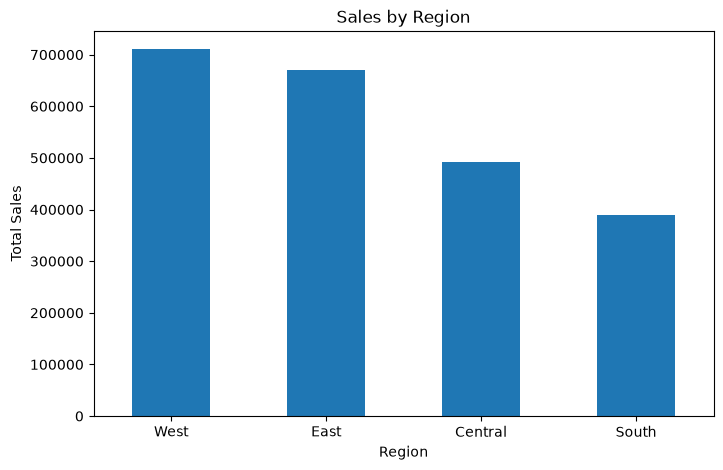

In [95]:
region_sales.plot(kind="bar", figsize=(8, 5))
plt.title("Sales by Region")
plt.xlabel("Region")
plt.ylabel("Total Sales")
plt.xticks(rotation=0)
plt.show()

In [96]:
category_sales = (
    df.groupby("Category")["Sales"]
    .sum()
    .sort_values(ascending=False)
)
print(category_sales)

top_products = (
    df.groupby("Product Name")["Sales"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)
print(top_products)

Category
Technology         827455.8730
Furniture          728658.5757
Office Supplies    705422.3340
Name: Sales, dtype: float64
Product Name
Canon imageCLASS 2200 Advanced Copier                                          61599.824
Fellowes PB500 Electric Punch Plastic Comb Binding Machine with Manual Bind    27453.384
Cisco TelePresence System EX90 Videoconferencing Unit                          22638.480
HON 5400 Series Task Chairs for Big and Tall                                   21870.576
GBC DocuBind TL300 Electric Binding System                                     19823.479
GBC Ibimaster 500 Manual ProClick Binding System                               19024.500
Hewlett Packard LaserJet 3310 Copier                                           18839.686
HP Designjet T520 Inkjet Large Format Printer - 24" Color                      18374.895
GBC DocuBind P400 Electric Binding System                                      17965.068
High Speed Automatic Electric Letter Opener             

In [97]:
def regional_analysis():
    result = (
        df.groupby("Region")["Sales"]
        .sum()
        .sort_values(ascending=False)
    )
    return result.to_dict()

def category_analysis():
    result = (
        df.groupby("Category")["Sales"]
        .sum()
        .sort_values(ascending=False)
    )

    return result.to_dict()

def top_products(n: int = 10):
    result = (
        df.groupby("Product Name")["Sales"]
        .sum()
        .sort_values(ascending=False)
        .head(n)
    )

    return result.to_dict()

print("Regional Sales:")
print(regional_analysis())
print("\nCategory Sales:")
print(category_analysis())
print("\nTop 5 Products:")
print(top_products(5))

Regional Sales:
{'West': 710219.6845, 'East': 669518.726, 'Central': 492646.9132, 'South': 389151.459}

Category Sales:
{'Technology': 827455.873, 'Furniture': 728658.5757, 'Office Supplies': 705422.334}

Top 5 Products:
{'Canon imageCLASS 2200 Advanced Copier': 61599.824, 'Fellowes PB500 Electric Punch Plastic Comb Binding Machine with Manual Bind': 27453.384000000002, 'Cisco TelePresence System EX90 Videoconferencing Unit': 22638.48, 'HON 5400 Series Task Chairs for Big and Tall': 21870.576, 'GBC DocuBind TL300 Electric Binding System': 19823.479}


In [98]:
from langchain.tools import tool

@tool
def analyze_business_data(analysis_type: str, n: int = 5) -> str:
    """
    Analyze business sales data.
    analysis_type can be regional, category, or top_products.
    n controls the number of top products returned.
    """

    if analysis_type == "regional":
        return str(regional_analysis())

    elif analysis_type == "category":
        return str(category_analysis())

    elif analysis_type == "top_products":
        return str(top_products(n))

    else:
        return "Invalid analysis type."

In [99]:
print(analyze_business_data.invoke({
    "analysis_type": "regional"
}))

print(analyze_business_data.invoke({
    "analysis_type": "category"
}))

print(analyze_business_data.invoke({
    "analysis_type": "top_products",
    "n": 5
}))

{'West': 710219.6845, 'East': 669518.726, 'Central': 492646.9132, 'South': 389151.459}
{'Technology': 827455.873, 'Furniture': 728658.5757, 'Office Supplies': 705422.334}
{'Canon imageCLASS 2200 Advanced Copier': 61599.824, 'Fellowes PB500 Electric Punch Plastic Comb Binding Machine with Manual Bind': 27453.384000000002, 'Cisco TelePresence System EX90 Videoconferencing Unit': 22638.48, 'HON 5400 Series Task Chairs for Big and Tall': 21870.576, 'GBC DocuBind TL300 Electric Binding System': 19823.479}


In [100]:
agent_tools = [
    search_documents,
    analyze_business_data
]
llm_with_tools = llm.bind_tools(agent_tools)
response = llm_with_tools.invoke(
    "What is Microsoft's business strategy?"
)
print(response.tool_calls)
response = llm_with_tools.invoke(
    "Which region generates the highest sales?"
)
print(response.tool_calls)

[{'name': 'search_documents', 'args': {'question': 'Microsoft business strategy mission vision'}, 'id': 'call_940464', 'type': 'tool_call'}]
[{'name': 'analyze_business_data', 'args': {'analysis_type': 'regional'}, 'id': 'call_1484502', 'type': 'tool_call'}]


In [101]:
from langchain.agents import create_agent
agent = create_agent(
    model=llm,
    tools=agent_tools,
    system_prompt="""
    You are an enterprise AI analytics assistant.

    Use search_documents for questions about information
    contained in company documents.

    Use analyze_business_data for questions about sales data.

    Always use tool results to support your answers.
    Never invent figures or facts.
    """
)
response = agent.invoke({
    "messages": [
        {"role": "user", "content": "Which region generates the highest sales?"}
    ]
})
print(response["messages"][-1].content)
response = agent.invoke({
    "messages": [
        {"role": "user", "content": "What is Microsoft's business strategy?"}
    ]
})
print(response["messages"][-1].content)
response = agent.invoke({
    "messages": [
        {
            "role": "user",
            "content": "Compare Microsoft's business strategy with our regional sales performance."
        }
    ]
})
print(response["messages"][-1].content)

[{'type': 'text', 'text': 'Based on the business sales data, the **West** region generates the highest sales with a total of **$710,219.68**. \n\nHere is the breakdown of sales by region for comparison:\n* **West:** $710,219.68\n* **East:** $669,518.73\n* **Central:** $492,646.91\n* **South:** $389,151.46', 'extras': {'signature': 'EmAKXgFpFH0Ts4+SI+dgN9oEUaFId0MDCMFS3eiXk1m6OJ40axkIGZfzN6JqSFF5hrnTudyorfpJz4HK/nivPbXd27oshKoZ+8t0r29hnfiCj/S9cU6B5d8swTj3p3fyVRU='}}]
[{'type': 'text', 'text': 'Microsoft’s business strategy is grounded in its core mission, strategic priorities, and organizational culture:\n\n* **Our Mission ("The Why"):** To empower every person and every organization on the planet to achieve more. Microsoft focuses on ensuring that customer success drives its own success, helping organizations build continuous learning systems and converting technological progress into broad economic benefit.\n* **Building a "Frontier Ecosystem" ("The What"):** As the company navigates 

In [102]:
def get_answer(response):
    content = response["messages"][-1].content

    if isinstance(content, list):
        return "\n".join(
            block["text"]
            for block in content
            if block.get("type") == "text"
        )

    return content

In [103]:
print(get_answer(response))

Based on Microsoft's 2026 Annual Report and our internal regional sales performance data, here is a comparison between Microsoft’s business strategy and our regional sales performance:

### **Microsoft’s Business Strategy**
* **Ecosystem & Platform-First Approach:** Microsoft focuses on building a broad "frontier ecosystem" (including platforms like Azure, Microsoft Foundry, Power Apps, and Office) where partners and customers can build value on top of their tech stack. Their core philosophy is to create broad economic surplus and deliver durable returns through indirect sales channels, partners, OEMs, and digital marketplaces.
* **Empowering Enterprise & AI Transformation:** Microsoft centers its strategy on enabling organizations of all sizes—from multinational enterprises to small and medium businesses—to leverage AI models, productivity tools, security offerings, and data sovereignty (e.g., via Microsoft Foundry and enterprise controls) to transform their work and outputs.

---

##

In [104]:
from langgraph.checkpoint.memory import InMemorySaver
memory = InMemorySaver()
agent = create_agent(
    model=llm,
    tools=agent_tools,
    system_prompt="""
    You are an enterprise AI analytics assistant.

    Use search_documents for document questions.
    Use analyze_business_data for sales analysis.

    Always support answers with tool results.
    Never invent information.
    """,
    checkpointer=memory
)
config = {
    "configurable": {
        "thread_id": "business_chat_1"
    }
}
response1 = agent.invoke(
    {
        "messages": [
            {"role": "user", "content": "Which region has the highest sales?"}
        ]
    },
    config=config
)

print(get_answer(response1))
response2 = agent.invoke(
    {
        "messages": [
            {"role": "user", "content": "What about the second highest?"}
        ]
    },
    config=config
)

print(get_answer(response2))
response3 = agent.invoke(
    {
        "messages": [
            {"role": "user", "content": "How much lower are its sales?"}
        ]
    },
    config=config
)

print(get_answer(response3))

Based on the sales data analysis, the **West** region has the highest sales with a total of **$710,219.68**. 

Here is the breakdown of sales across all regions:
* **West:** $710,219.68
* **East:** $669,518.73
* **Central:** $492,646.91
* **South:** $389,151.46
Based on the sales data analysis, the **East** region has the second highest sales with a total of **$669,518.73**.
Based on the regional sales data:
* **West region sales (highest):** $710,219.68
* **East region sales (second highest):** $669,518.73

The East region's sales are **$40,700.96** lower than the West region's sales.


In [ ]:
%pip install -U langgraph-checkpoint-sqlite

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: C:\Users\KARTIK SRIBVASTAVA\AppData\Local\Python\pythoncore-3.14-64\python.exe -m pip install --upgrade pip


In [105]:
import sqlite3
from langgraph.checkpoint.sqlite import SqliteSaver
connection = sqlite3.connect(
    "data/chat_memory.db",
    check_same_thread=False
)
checkpointer = SqliteSaver(connection)
checkpointer.setup()
agent = create_agent(
    model=llm,
    tools=agent_tools,
    system_prompt="""
    You are an enterprise AI analytics assistant.

    Use search_documents for document questions.
    Use analyze_business_data for sales analysis.

    Never invent information.
    """,
    checkpointer=checkpointer
)
config = {
    "configurable": {
        "thread_id": "customer_001"
    }
}

response = agent.invoke(
    {
        "messages": [
            {"role": "user", "content": "Which region has the highest sales?"}
        ]
    },
    config=config
)
print(get_answer(response))
response = agent.invoke(
    {
        "messages": [
            {"role": "user", "content": "What is the second highest?"}
        ]
    },
    config=config
)
print(get_answer(response))

Based on the sales analysis, the **West** region has the highest sales with a total of $710,219.68.
Based on the sales analysis, the **East** region has the second highest sales with a total of $669,518.73.


In [106]:
from typing import TypedDict

class AgentState(TypedDict):
    question: str
    route: str
    context: str
    answer: str

def router_node(state: AgentState):

    prompt = f"""
    Decide which capability is needed.

    Question: {state['question']}

    Reply with exactly one word:
    documents, analytics, or both.
    """

    response = llm.invoke(prompt)

    route = response.content[0]["text"].strip().lower()

    return {"route": route}

test_state = {
    "question": "Which region has the highest sales?",
    "route": "",
    "context": "",
    "answer": ""
}

print(router_node(test_state))



{'route': 'analytics'}


In [116]:
def both_node(state: AgentState):

    # Search company documents
    doc_result = search_documents.invoke({
        "question": state["question"]
    })

    # Identify the required business analysis
    prompt = f"""
    Choose the correct analysis for this question.

    Question: {state['question']}

    Return only one:
    regional, category, top_products
    """

    response = llm.invoke(prompt)
    analysis_type = response.content[0]["text"].strip().lower()

    # Perform business analysis
    analytics_result = analyze_business_data.invoke({
        "analysis_type": analysis_type,
        "n": 5
    })

    return {
        "context": f"""
        DOCUMENT INFORMATION:
        {doc_result}

        BUSINESS ANALYTICS:
        {analytics_result}
        """
    }
builder.add_edge("both", "response")

In [118]:
def document_node(state: AgentState):

    result = search_documents.invoke({
        "question": state["question"]
    })

    return {"context": result}

def analytics_node(state: AgentState):

    prompt = f"""
    Choose the correct analysis for this question.

    Question: {state['question']}

    Return only one:
    regional, category, top_products
    """

    response = llm.invoke(prompt)
    analysis_type = response.content[0]["text"].strip().lower()

    result = analyze_business_data.invoke({
        "analysis_type": analysis_type,
        "n": 5
    })

    return {"context": result}

In [120]:
def both_node(state: AgentState):

    doc_result = search_documents.invoke({
        "question": state["question"]
    })

    prompt = f"""
    Choose the correct analysis for this question.

    Question: {state['question']}

    Return only one:
    regional, category, top_products
    """

    response = llm.invoke(prompt)
    analysis_type = response.content[0]["text"].strip().lower()

    analytics_result = analyze_business_data.invoke({
        "analysis_type": analysis_type,
        "n": 5
    })

    return {
        "context": f"""
        DOCUMENT INFORMATION:
        {doc_result}

        BUSINESS ANALYTICS:
        {analytics_result}
        """
    }

In [121]:
def response_node(state: AgentState):

    prompt = f"""
    Answer the user's question using the information below.

    Question: {state['question']}

    Retrieved information:
    {state['context']}

    Do not invent facts or figures.
    """

    response = llm.invoke(prompt)

    return {"answer": response.content[0]["text"]}

In [122]:
from langgraph.graph import StateGraph, START, END

builder = StateGraph(AgentState)

builder.add_node("router", router_node)
builder.add_node("documents", document_node)
builder.add_node("analytics", analytics_node)
builder.add_node("both", both_node)
builder.add_node("response", response_node)

builder.add_edge(START, "router")

builder.add_conditional_edges(
    "router",
    lambda state: state["route"],
    {
        "documents": "documents",
        "analytics": "analytics",
        "both": "both"
    }
)

builder.add_edge("documents", "response")
builder.add_edge("analytics", "response")
builder.add_edge("both", "response")
builder.add_edge("response", END)

workflow = builder.compile()

In [123]:
result = workflow.invoke({
    "question": "Compare Microsoft's business strategy with our regional sales performance.",
    "route": "",
    "context": "",
    "answer": ""
})

print(result["answer"])

Based on the provided information, the retrieved documents do not contain data regarding regional sales performance. Therefore, a comparison between Microsoft's business strategy and regional sales performance cannot be made using the provided sources. 

However, the provided information does detail aspects of Microsoft's business strategy and culture (such as focusing on Super Intelligence, responsible building, shared benefits, and maintaining a "growth mindset" through curiosity and reinvention), as well as financial performance data like stock returns and reportable segments (Productivity and Business Processes, Intelligent Cloud, and More Personal Computing), along with general business analytics by product category (Technology, Furniture, and Office Supplies).


In [124]:
result = workflow.invoke({
    "question": "Which region has the highest sales?",
    "route": "",
    "context": "",
    "answer": ""
})

print(result["answer"])

Based on the provided information, the **West** region has the highest sales (710219.6845).


In [125]:
result = workflow.invoke({
    "question": "What is Microsoft's business strategy?",
    "route": "",
    "context": "",
    "answer": ""
})

print(result["answer"])

Based on the provided information, Microsoft's business strategy and approach include:

* **Building a Frontier Ecosystem:** Microsoft leverages its broad tech stack, diverse businesses, and platform- and partner-first approach to build a frontier ecosystem. This enables others to build more value on top of and through the ecosystem than is captured inside, creating broad economic surplus and durable returns for investors.
* **Converting Technological Progress into Economic Benefit:** Aligning everything they do to convert technological progress into real-world outcomes and economic benefits for countries, communities, and companies everywhere. 
* **Focusing on Core Elements:** Staying grounded in the "why" of their mission (empowering every person and organization to achieve more, and helping customers succeed), the "what" of their strategic priorities, and the "how" of their culture.


In [126]:
result = workflow.invoke({
    "question": "Compare Microsoft's business strategy with our regional sales performance.",
    "route": "",
    "context": "",
    "answer": ""
})

print(result["answer"])

Based on the provided information, the retrieved documents discuss Microsoft's business strategy (such as focusing on Super Intelligence, a growth mindset, and reportable segments like Productivity and Business Processes, Intelligent Cloud, and More Personal Computing) and provide regional/category-based business analytics data (such as Technology at $827,455.873, Furniture at $728,658.5757, and Office Supplies at $705,422.334). However, the provided text **does not contain information comparing Microsoft's business strategy with regional sales performance**. Therefore, a direct comparison cannot be made using the supplied data.


In [127]:
def router_node(state: AgentState):

    prompt = f"""
    Decide which capability is needed.

    Question: {state['question']}

    Reply with exactly one word:
    documents, analytics, or both.
    """

    response = llm.invoke(prompt)
    route = response.content[0]["text"].strip().lower()

    if route not in ["documents", "analytics", "both"]:
        route = "both"

    return {"route": route}

test_state = {
    "question": "Which region has the highest sales?",
    "route": "",
    "context": "",
    "answer": ""
}

print(router_node(test_state))

{'route': 'analytics'}


In [128]:
def document_node(state: AgentState):

    try:
        result = search_documents.invoke({
            "question": state["question"]
        })

        return {"context": result}

    except Exception as e:
        return {"context": f"Document search failed: {e}"}
    
def analytics_node(state: AgentState):

    try:
        prompt = f"""
        Choose the correct analysis for this question.

        Question: {state['question']}

        Return only one:
        regional, category, top_products
        """

        response = llm.invoke(prompt)
        analysis_type = response.content[0]["text"].strip().lower()

        if analysis_type not in ["regional", "category", "top_products"]:
            return {"context": "Could not identify the required analysis."}

        result = analyze_business_data.invoke({
            "analysis_type": analysis_type,
            "n": 5
        })

        return {"context": result}

    except Exception as e:
        return {"context": f"Analytics failed: {e}"}
    
def both_node(state: AgentState):

    try:
        doc_result = search_documents.invoke({
            "question": state["question"]
        })

        prompt = f"""
        Choose the correct analysis for this question.

        Question: {state['question']}

        Return only one:
        regional, category, top_products
        """

        response = llm.invoke(prompt)
        analysis_type = response.content[0]["text"].strip().lower()

        if analysis_type not in ["regional", "category", "top_products"]:
            return {"context": "Could not identify the required analysis."}

        analytics_result = analyze_business_data.invoke({
            "analysis_type": analysis_type,
            "n": 5
        })

        return {
            "context": f"""
            DOCUMENT INFORMATION:
            {doc_result}

            BUSINESS ANALYTICS:
            {analytics_result}
            """
        }

    except Exception as e:
        return {"context": f"Combined analysis failed: {e}"}

In [129]:
builder = StateGraph(AgentState)

builder.add_node("router", router_node)
builder.add_node("documents", document_node)
builder.add_node("analytics", analytics_node)
builder.add_node("both", both_node)
builder.add_node("response", response_node)

builder.add_edge(START, "router")

builder.add_conditional_edges(
    "router",
    lambda state: state["route"],
    {
        "documents": "documents",
        "analytics": "analytics",
        "both": "both"
    }
)

builder.add_edge("documents", "response")
builder.add_edge("analytics", "response")
builder.add_edge("both", "response")
builder.add_edge("response", END)

workflow = builder.compile()

In [130]:
from typing import TypedDict
class AgentState(TypedDict):
    question: str
    route: str
    context: str
    answer: str
    history: list
    
def response_node(state: AgentState):

    prompt = f"""
    You are an enterprise AI analytics assistant.

    Previous conversation:
    {state['history']}

    Current question:
    {state['question']}

    Available information:
    {state['context']}

    Answer accurately using the available information.
    Do not invent facts or figures.
    """

    response = llm.invoke(prompt)
    answer = response.content[0]["text"]

    history = state["history"] + [
        {
            "question": state["question"],
            "answer": answer
        }
    ]

    return {
        "answer": answer,
        "history": history
    }
    
import sqlite3
from langgraph.checkpoint.sqlite import SqliteSaver

connection = sqlite3.connect(
    "data/workflow_memory.db",
    check_same_thread=False
)

checkpointer = SqliteSaver(connection)
checkpointer.setup()

workflow = builder.compile(checkpointer=checkpointer)

In [131]:
config = {
    "configurable": {
        "thread_id": "business_chat_01"
    }
}

result = workflow.invoke({
    "question": "Which region has the highest sales?",
    "route": "",
    "context": "",
    "answer": "",
    "history": []
}, config=config)

print(result["answer"])

Based on the provided information, the **West** region has the highest sales, with a total of 710,219.6845.


In [132]:
result = workflow.invoke({
    "question": "What is the second highest region?"
}, config=config)

print(result["answer"])

Based on the provided information, the second highest region is the East, with a value of 669518.726.


In [133]:
from langchain.tools import tool

@tool
def search_documents(question: str) -> str:
    """Search company documents and return relevant information with citations."""

    results = retriever.invoke(question)

    context = ""

    for doc in results:

        source = doc.metadata.get("source", "Unknown")
        source = source.replace("\\", "/").split("/")[-1]

        page = doc.metadata.get("page", "Unknown")

        if isinstance(page, int):
            page += 1

        context += f"""
        Source: {source}
        Page: {page}
        Content: {doc.page_content}

        """

    return context

In [134]:
def response_node(state: AgentState):

    prompt = f"""
    You are an enterprise AI analytics assistant.

    Previous conversation:
    {state['history']}

    Current question:
    {state['question']}

    Available information:
    {state['context']}

    Instructions:
    - Answer using the available information.
    - Do not invent facts or figures.
    - For document-based claims, cite the source and page.
    - Use this citation format: [Source: filename, Page: number].
    - If information is unavailable, say so.
    """

    response = llm.invoke(prompt)
    answer = response.content[0]["text"]

    history = state["history"] + [
        {
            "question": state["question"],
            "answer": answer
        }
    ]

    return {
        "answer": answer,
        "history": history
    }

In [135]:
builder = StateGraph(AgentState)

builder.add_node("router", router_node)
builder.add_node("documents", document_node)
builder.add_node("analytics", analytics_node)
builder.add_node("both", both_node)
builder.add_node("response", response_node)

builder.add_edge(START, "router")

builder.add_conditional_edges(
    "router",
    lambda state: state["route"],
    {
        "documents": "documents",
        "analytics": "analytics",
        "both": "both"
    }
)

builder.add_edge("documents", "response")
builder.add_edge("analytics", "response")
builder.add_edge("both", "response")
builder.add_edge("response", END)

workflow = builder.compile(checkpointer=checkpointer)

In [136]:
config = {
    "configurable": {
        "thread_id": "citation_test_01"
    }
}

result = workflow.invoke({
    "question": "What is Microsoft's business strategy?",
    "route": "",
    "context": "",
    "answer": "",
    "history": []
}, config=config)

print(result["answer"])

Based on Microsoft's 2026 Annual Report, the company's business strategy and approach center around the following key elements:

* **Building a Frontier Ecosystem:** Microsoft leverages its broad tech stack, diverse businesses, and platform- and partner-first approach to build a "frontier ecosystem." This ecosystem is designed to enable others to build more value on top of and through it than is captured inside, creating broad economic surplus and durable returns for investors [Source: 2026_AnnualReport.pdf, Page: 3].
* **Converting Technological Progress into Economic Benefit:** As the company enters the "Super Intelligence era," its strategy is focused on converting technological progress into real-world economic benefits for every country, community, and company, helping organizations apply technology to innovate and grow [Source: 2026_AnnualReport.pdf, Page: 3].
* **Core Mission and Commitments:** Microsoft's corporate responsibility and commitments are central to its mission "to e

In [137]:
query = "What is Microsoft's business strategy?"

results = retriever.invoke(query)

for i, doc in enumerate(results):
    print(f"\nResult {i+1}")
    print("Source:", doc.metadata["source"])
    print("Page:", doc.metadata["page"] + 1)
    print("Content:", doc.page_content[:300])


Result 1
Source: data\documents\2026_AnnualReport.pdf
Page: 3
Content: 1 
 
Building the Frontier Ecosystem 
Dear shareholders, colleagues, customers, and partners: 
For Microsoft, the central question as we enter this Super Intelligence era is not just how big the opportunity becomes, but 
how we deliver the real-world outcomes that every country, community, and compa

Result 2
Source: data\documents\2026_AnnualReport.pdf
Page: 23
Content: 21 
MANAGEMENT’S DISCUSSION AND ANALYSIS OF FINANCIAL CONDITION AND 
RESULTS OF OPERATIONS 
The following Management’s Discussion and Analysis of Financial Condition and Results of Operations (“MD&A”) is 
intended to help the reader understand the results of operations and financial condition of Mic

Result 3
Source: data\documents\2026_AnnualReport.pdf
Page: 86
Content: https://www.microsoft.com/en-us/investor/annual-reports  
Environmental, Social, and Governance (ESG)/Corporate 
Responsibility  
Strong governance, ethical standards, and transpar

In [138]:
query = "What are Microsoft's financial performance and revenue results?"

results = retriever.invoke(query)

for i, doc in enumerate(results):
    print(f"\nResult {i+1}")
    print("Page:", doc.metadata["page"] + 1)
    print("Content:", doc.page_content[:300])


Result 1
Page: 3
Content: the value an d usage of our services. Together, these efforts help our customers apply technology to innovate and grow, 
while strengthening our ability to deliver long-term value to shareholders. 
This is already translating into strong financial performance. Fiscal year 2026 was another record yea

Result 2
Page: 23
Content: 21 
MANAGEMENT’S DISCUSSION AND ANALYSIS OF FINANCIAL CONDITION AND 
RESULTS OF OPERATIONS 
The following Management’s Discussion and Analysis of Financial Condition and Results of Operations (“MD&A”) is 
intended to help the reader understand the results of operations and financial condition of Mic

Result 3
Page: 76
Content: respectively, and were expensed as contributed.  
NOTE 18 — SEGMENT INFORMATION AND GEOGRAPHIC DATA  
In its operation of the business, management, including our chief operating decision maker (“CODM”), who is also our Chief 
Executive Officer, reviews certain financial information, including segmen

Result 4
Page

In [155]:
from typing import TypedDict

class AgentState(TypedDict):
    question: str
    route: str
    context: str
    answer: dict
    history: list
    
from pydantic import BaseModel
from typing import List

class AgentResponse(BaseModel):
    answer: str
    sources: List[str]
    insights: List[str]

structured_llm = llm.with_structured_output(AgentResponse)

In [156]:
def response_node(state: AgentState):

    prompt = f"""
    You are an enterprise AI analytics assistant.

    Previous conversation:
    {state['history']}

    Current question:
    {state['question']}

    Available information:
    {state['context']}

    Instructions:
    - Answer using available information.
    - Do not invent facts or figures.
    - Include document filenames and page numbers in sources.
    - Include relevant business findings in insights.
    - If information is unavailable, say so.
    """

    response = structured_llm.invoke(prompt)

    answer = response.model_dump()

    history = state["history"] + [
        {
            "question": state["question"],
            "answer": answer["answer"]
        }
    ]

    return {
        "answer": answer,
        "history": history
    }

In [157]:
builder = StateGraph(AgentState)

builder.add_node("router", router_node)
builder.add_node("documents", document_node)
builder.add_node("analytics", analytics_node)
builder.add_node("both", both_node)
builder.add_node("response", response_node)

builder.add_edge(START, "router")

builder.add_conditional_edges(
    "router",
    lambda state: state["route"],
    {
        "documents": "documents",
        "analytics": "analytics",
        "both": "both"
    }
)

builder.add_edge("documents", "response")
builder.add_edge("analytics", "response")
builder.add_edge("both", "response")
builder.add_edge("response", END)

workflow = builder.compile(checkpointer = checkpointer)

In [158]:
result = workflow.invoke({
    "question": "What is Microsoft's business strategy?",
    "route": "",
    "context": "",
    "answer": {},
    "history": []
}, config={
    "configurable": {
        "thread_id": "structured_test_03"
    }
})

print(type(result["answer"]))
print(result["answer"])

<class 'dict'>
{'answer': "Microsoft's business strategy centers on building a frontier ecosystem to convert technological progress in the Super Intelligence era into economic benefit for everyone. They leverage a broad tech stack, diverse businesses, and a platform- and partner-first approach to enable others to create more value than is captured internally, generating broad economic surplus and durable investor returns.", 'sources': ['2026_AnnualReport.pdf (Page 3)', '2026_AnnualReport.pdf (Page 86)'], 'insights': ['Microsoft aligns its strategy around the Super Intelligence era by focusing on delivering real-world outcomes and economic benefits globally.', 'The company utilizes a platform- and partner-first approach designed to help customers and partners build value on top of its ecosystem.', "Microsoft's mission remains empowering every person and organization to achieve more, supported by strong ESG and corporate responsibility commitments."]}


In [159]:
%pip install fastapi uvicorn

  Using cached fastapi-0.162.0-py3-none-any.whl.metadata (26 kB)
  Using cached uvicorn-0.54.0-py3-none-any.whl.metadata (6.6 kB)
  Using cached starlette-1.10.0-py3-none-any.whl.metadata (6.6 kB)
Using cached fastapi-0.162.0-py3-none-any.whl (148 kB)
Using cached uvicorn-0.54.0-py3-none-any.whl (87 kB)
Using cached starlette-1.10.0-py3-none-any.whl (80 kB)

   ---------------------------------------- 0/4 [uvicorn]
   ---------------------------------------- 0/4 [uvicorn]
   ---------------------------------------- 0/4 [uvicorn]
   ---------- ----------------------------- 1/4 [opentelemetry-api]
   ---------- ----------------------------- 1/4 [opentelemetry-api]
   -------------------- ------------------- 2/4 [starlette]
   -------------------- ------------------- 2/4 [starlette]
   -------------------- ------------------- 2/4 [starlette]
   ------------------------------ --------- 3/4 [fastapi]
   ------------------------------ --------- 3/4 [fastapi]
   ------------------------------

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.

[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: C:\Users\KARTIK SRIBVASTAVA\AppData\Local\Python\pythoncore-3.14-64\python.exe -m pip install --upgrade pip
